# UPI Transaction Analysis — Python Analysis
## Steps 5–7: SQL Extraction, Data Cleaning, EDA & Statistical Analysis

**Prepared by:** Chinmaya Panigrahi  
**Registration ID:** 24CRD05066

### Notebook Scope
- Step 5 — Connect Python to MySQL and validate extracted datasets
- Step 6 — Data cleaning, transformation and exploratory data analysis
- Step 7 — Statistical analysis and hypothesis testing

## 1. Install required libraries

In [1]:
%pip install pandas numpy matplotlib seaborn sqlalchemy pymysql scipy statsmodels

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import pymysql

from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from getpass import getpass

## 3. Create a secure MySQL connection

In [3]:
DB_USER = "root"          # change only if your MySQL username is different
DB_HOST = "localhost"
DB_PORT = 3306
DB_NAME = "upi_capstone_db"

DB_PASSWORD = getpass("Enter MySQL password: ")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)

engine = create_engine(connection_url)

Enter MySQL password:  ········


## 4. Test the connection

In [4]:
connection_test = pd.read_sql_query(
    "SELECT DATABASE() AS database_name, VERSION() AS mysql_version;",
    engine
)
connection_test

,database_name,mysql_version
0,upi_capstone_db,9.7.0


## 5. Validate available SQL tables

In [5]:
tables_df = pd.read_sql_query("SHOW TABLES;", engine)
tables_df

,Tables_in_upi_capstone_db
0,customer_feedback_surveys
1,customer_master
2,device_info
3,fraud_alert_history
4,merchant_info
5,upi_account_details
6,upi_transaction_history


## 6. Load all seven SQL tables into Pandas DataFrames

In [6]:
table_names = [
    "customer_master",
    "device_info",
    "upi_account_details",
    "merchant_info",
    "upi_transaction_history",
    "customer_feedback_surveys",
    "fraud_alert_history",
]

dfs = {
    table: pd.read_sql_query(f"SELECT * FROM {table};", engine)
    for table in table_names
}

customer_df = dfs["customer_master"]
device_df = dfs["device_info"]
upi_account_df = dfs["upi_account_details"]
merchant_df = dfs["merchant_info"]
transaction_df = dfs["upi_transaction_history"]
feedback_df = dfs["customer_feedback_surveys"]
fraud_alert_df = dfs["fraud_alert_history"]

## 7. Validate DataFrame shapes and expected record counts

In [7]:
expected_rows = {
    "customer_master": 10000,
    "device_info": 12000,
    "upi_account_details": 12000,
    "merchant_info": 500,
    "upi_transaction_history": 100000,
    "customer_feedback_surveys": 4000,
    "fraud_alert_history": 2000,
}

validation_rows = []
for table, df in dfs.items():
    actual = len(df)
    expected = expected_rows[table]
    validation_rows.append({
        "table": table,
        "expected_rows": expected,
        "python_rows": actual,
        "columns": df.shape[1],
        "status": "PASS" if actual == expected else "REVIEW"
    })

row_validation_df = pd.DataFrame(validation_rows)
row_validation_df

,table,expected_rows,python_rows,columns,status
0,customer_master,10000,10000,9,PASS
1,device_info,12000,12000,6,PASS
2,upi_account_details,12000,12000,6,PASS
3,merchant_info,500,500,6,PASS
4,upi_transaction_history,100000,100000,15,PASS
5,customer_feedback_surveys,4000,4000,7,PASS
6,fraud_alert_history,2000,2000,7,PASS


## 8. Validate schemas extracted into Pandas

In [8]:
for table, df in dfs.items():
    print(f"\n--- {table} ---")
    print(df.dtypes)


--- customer_master ---
customer_id          object
full_name            object
age                   int64
gender               object
region               object
date_joined          object
is_business_user      int64
risk_score          float64
mobile_number        object
dtype: object

--- device_info ---
device_id              object
customer_id            object
device_type            object
app_version            object
is_rooted               int64
last_active    datetime64[ns]
dtype: object

--- upi_account_details ---
upi_id          object
customer_id     object
bank_name       object
account_type    object
date_added      object
status          object
dtype: object

--- merchant_info ---
merchant_id       object
merchant_name     object
merchant_type     object
region            object
onboard_date      object
risk_score       float64
dtype: object

--- upi_transaction_history ---
transaction_id              object
upi_id                      object
customer_id            

## 9. SQL-side schema metadata check

In [9]:
schema_df = pd.read_sql_query(
    """
    SELECT
        TABLE_NAME,
        COLUMN_NAME,
        DATA_TYPE,
        IS_NULLABLE,
        COLUMN_KEY
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'upi_capstone_db'
    ORDER BY TABLE_NAME, ORDINAL_POSITION;
    """,
    engine
)
schema_df

,TABLE_NAME,COLUMN_NAME,DATA_TYPE,IS_NULLABLE,COLUMN_KEY
0,customer_feedback_surveys,feedback_id,varchar,NO,PRI
1,customer_feedback_surveys,customer_id,varchar,NO,MUL
2,customer_feedback_surveys,date_submitted,date,NO,
3,customer_feedback_surveys,feedback_text,text,YES,
4,customer_feedback_surveys,satisfaction_score,tinyint,NO,
5,customer_feedback_surveys,issue_type,varchar,NO,
6,customer_feedback_surveys,resolved,tinyint,NO,
7,customer_master,customer_id,varchar,NO,PRI
8,customer_master,full_name,varchar,NO,
9,customer_master,age,int,NO,


## 10. Demonstrate pandas.read_sql_query

In [10]:
sample_query = pd.read_sql_query(
    """
    SELECT
        transaction_id,
        customer_id,
        amount,
        status,
        fraud_flag
    FROM upi_transaction_history
    LIMIT 10;
    """,
    engine
)

sample_query

,transaction_id,customer_id,amount,status,fraud_flag
0,txn10000000,cust101488,9.88,success,0
1,txn10000001,cust107876,76.25,success,0
2,txn10000002,cust100901,26.44,success,0
3,txn10000003,cust105890,84.43,success,0
4,txn10000004,cust106780,10.33,success,0
5,txn10000005,cust102097,37.61,success,0
6,txn10000006,cust108896,77.74,failed,0
7,txn10000007,cust102418,47.46,success,0
8,txn10000008,cust109937,19.94,success,0
9,txn10000009,cust108084,13.95,success,0


## 11. Final Step 5 validation summary

In [11]:
all_pass = (row_validation_df["status"] == "PASS").all()
print("All seven tables extracted successfully:", all_pass)
print("Total rows loaded into Pandas:", sum(len(df) for df in dfs.values()))

All seven tables extracted successfully: True
Total rows loaded into Pandas: 140500


### Expected final result
- All 7 tables are accessible from Python.
- Every DataFrame row count matches the SQL source table.
- Total records extracted into Pandas = **140,500**.
- Schema and dtypes are visible for review before Step 6 cleaning and EDA.

# Step 6 — Data Cleaning, Transformations & Enhanced EDA

### Objective
Prepare the SQL-extracted datasets for reliable analytical use, document
justified cleaning and transformation decisions, create assignment-defined
derived metrics, and conduct exploratory analysis across transaction,
customer, merchant, device, regional, and fraud dimensions.

> **Analytical principle:** Original business values are preserved wherever
possible. Missing values, outliers, and transformations are handled only
when justified by the data and assignment requirements.

## 6.1 Analysis Setup & Working Copies

This section prepares the Python analysis environment and creates working
copies of the SQL-extracted DataFrames so that the original extraction
results remain unchanged.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

### 6.1.1 Create Working Copies of SQL-Extracted DataFrames

The original Step-5 DataFrames are preserved as the SQL extraction layer.
Separate working copies are created for cleaning, transformation, and EDA.

In [13]:
customer_clean = customer_df.copy()
device_clean = device_df.copy()
upi_account_clean = upi_account_df.copy()
merchant_clean = merchant_df.copy()
transaction_clean = transaction_df.copy()
feedback_clean = feedback_df.copy()
fraud_alert_clean = fraud_alert_df.copy()

### 6.1.2 Baseline Shape Validation

Before making any transformations, confirm that the working copies retain
the same row and column counts as the successfully validated SQL extraction.

In [14]:
clean_dfs = {
    "customer_master": customer_clean,
    "device_info": device_clean,
    "upi_account_details": upi_account_clean,
    "merchant_info": merchant_clean,
    "upi_transaction_history": transaction_clean,
    "customer_feedback_surveys": feedback_clean,
    "fraud_alert_history": fraud_alert_clean
}

for name, df in clean_dfs.items():
    print(f"{name}: {df.shape}")

customer_master: (10000, 9)
device_info: (12000, 6)
upi_account_details: (12000, 6)
merchant_info: (500, 6)
upi_transaction_history: (100000, 15)
customer_feedback_surveys: (4000, 7)
fraud_alert_history: (2000, 7)


## 6.2 Data Quality Assessment

The extracted datasets are assessed for missing values, contextual nulls,
and duplicate records before any cleaning action is taken.

### 6.2.1 Missing-Value Profile

In [15]:
missing_report = []

for table_name, df in clean_dfs.items():
    for column in df.columns:

        missing_count = df[column].isna().sum()

        if missing_count > 0:
            missing_report.append({
                "table": table_name,
                "column": column,
                "missing_count": missing_count,
                "missing_percentage": round(
                    missing_count / len(df) * 100, 2
                )
            })

missing_report_df = pd.DataFrame(missing_report)

missing_report_df

,table,column,missing_count,missing_percentage
0,upi_transaction_history,merchant_id,69851,69.85
1,upi_transaction_history,failure_reason,94129,94.13
2,fraud_alert_history,resolution_date,248,12.40


### 6.2.2 Contextual Null Validation

Missing values are evaluated against their related business fields before
deciding whether they require treatment.

The following checks determine whether:

- missing `merchant_id` values correspond to transaction types where a
  merchant is not applicable;
- missing `failure_reason` values correspond to non-failed transactions;
- missing `resolution_date` values correspond to unresolved fraud alerts.

In [16]:
pd.crosstab(
    transaction_clean["transaction_type"],
    transaction_clean["merchant_id"].isna(),
    margins=True
)

merchant_id,False,True,All
transaction_type,,,
bill_pay,5052,0,5052
merchant_payment,25097,0,25097
receive,0,34819,34819
send,0,35032,35032
All,30149,69851,100000


In [17]:
pd.crosstab(
    transaction_clean["status"],
    transaction_clean["failure_reason"].isna(),
    margins=True
)

failure_reason,False,True,All
status,,,
failed,5871,0,5871
pending,0,1989,1989
success,0,92140,92140
All,5871,94129,100000


In [18]:
pd.crosstab(
    fraud_alert_clean["resolved"],
    fraud_alert_clean["resolution_date"].isna(),
    margins=True
)

resolution_date,False,True,All
resolved,,,
0,0,248,248
1,1752,0,1752
All,1752,248,2000


### Missing-Value Treatment Decision

The observed missing values are structurally consistent with their business
context and therefore are not treated as data-quality errors.

- `merchant_id` is retained as null where the transaction does not involve
  a merchant.
- `failure_reason` is retained as null for non-failed transactions.
- `resolution_date` is retained as null for unresolved fraud alerts.

No rows are removed and no arbitrary values are imputed. This preserves
the original meaning of the supplied data.

### 6.2.3 Duplicate Record Assessment

All seven extracted datasets are checked for exact duplicate rows before
further transformation.

In [19]:
duplicate_summary = []

for table_name, df in clean_dfs.items():

    duplicate_summary.append({
        "table": table_name,
        "duplicate_rows": df.duplicated().sum()
    })

duplicate_summary_df = pd.DataFrame(duplicate_summary)

duplicate_summary_df

,table,duplicate_rows
0,customer_master,0
1,device_info,0
2,upi_account_details,0
3,merchant_info,0
4,upi_transaction_history,0
5,customer_feedback_surveys,0
6,fraud_alert_history,0


**Result:** No duplicate rows were detected in any of the seven datasets.
Therefore, no duplicate-removal operation is required.

## 6.3 Data Type & Domain Standardization

SQL data types do not always map directly to the most analytically useful
Pandas data types. Date fields, Boolean indicators, and numerical domains
are therefore validated and standardized before EDA.

### 6.3.1 Date and DateTime Standardization

In [20]:
customer_clean["date_joined"] = pd.to_datetime(
    customer_clean["date_joined"],
    errors="coerce"
)

upi_account_clean["date_added"] = pd.to_datetime(
    upi_account_clean["date_added"],
    errors="coerce"
)

merchant_clean["onboard_date"] = pd.to_datetime(
    merchant_clean["onboard_date"],
    errors="coerce"
)

feedback_clean["date_submitted"] = pd.to_datetime(
    feedback_clean["date_submitted"],
    errors="coerce"
)

In [21]:
device_clean["last_active"] = pd.to_datetime(
    device_clean["last_active"],
    errors="coerce"
)

transaction_clean["timestamp"] = pd.to_datetime(
    transaction_clean["timestamp"],
    errors="coerce"
)

fraud_alert_clean["alert_date"] = pd.to_datetime(
    fraud_alert_clean["alert_date"],
    errors="coerce"
)

fraud_alert_clean["resolution_date"] = pd.to_datetime(
    fraud_alert_clean["resolution_date"],
    errors="coerce"
)

In [22]:
date_columns = {
    "customer.date_joined": customer_clean["date_joined"],
    "upi.date_added": upi_account_clean["date_added"],
    "merchant.onboard_date": merchant_clean["onboard_date"],
    "feedback.date_submitted": feedback_clean["date_submitted"],
    "device.last_active": device_clean["last_active"],
    "transaction.timestamp": transaction_clean["timestamp"],
    "fraud.alert_date": fraud_alert_clean["alert_date"]
}

for name, series in date_columns.items():
    print(name, "missing after conversion:", series.isna().sum())

customer.date_joined missing after conversion: 0
upi.date_added missing after conversion: 0
merchant.onboard_date missing after conversion: 0
feedback.date_submitted missing after conversion: 0
device.last_active missing after conversion: 0
transaction.timestamp missing after conversion: 0
fraud.alert_date missing after conversion: 0


**Result:** All required date and DateTime fields were converted successfully
without introducing unexpected missing values. Legitimate null
`resolution_date` values remain unchanged.

### 6.3.2 Boolean Field Standardization

Boolean fields imported from MySQL as `0/1` integers are converted to Python
Boolean values to improve semantic clarity during analysis.

In [23]:
boolean_validation = {
    "is_business_user": sorted(customer_clean["is_business_user"].unique()),
    "is_rooted": sorted(device_clean["is_rooted"].unique()),
    "fraud_flag": sorted(transaction_clean["fraud_flag"].unique()),
    "reversal_flag": sorted(transaction_clean["reversal_flag"].unique()),
    "feedback_resolved": sorted(feedback_clean["resolved"].unique()),
    "alert_resolved": sorted(fraud_alert_clean["resolved"].unique())
}

boolean_validation

{'is_business_user': [np.int64(0), np.int64(1)],
 'is_rooted': [np.int64(0), np.int64(1)],
 'fraud_flag': [np.int64(0), np.int64(1)],
 'reversal_flag': [np.int64(0), np.int64(1)],
 'feedback_resolved': [np.int64(0), np.int64(1)],
 'alert_resolved': [np.int64(0), np.int64(1)]}

**Result:** All Boolean source fields contained only the expected `0/1` values. They can therefore be safely converted to Python Boolean type.

In [24]:
customer_clean["is_business_user"] = (
    customer_clean["is_business_user"].astype(bool)
)

device_clean["is_rooted"] = (
    device_clean["is_rooted"].astype(bool)
)

transaction_clean["fraud_flag"] = (
    transaction_clean["fraud_flag"].astype(bool)
)

transaction_clean["reversal_flag"] = (
    transaction_clean["reversal_flag"].astype(bool)
)

feedback_clean["resolved"] = (
    feedback_clean["resolved"].astype(bool)
)

fraud_alert_clean["resolved"] = (
    fraud_alert_clean["resolved"].astype(bool)
)

In [25]:
transaction_clean[["fraud_flag", "reversal_flag"]].dtypes

fraud_flag       bool
reversal_flag    bool
dtype: object

### 6.3.3 Numerical Domain Validation

Numerical fields with assignment-defined or logically required ranges are
validated before transformation.

Checks include:

- customer `risk_score` within 0–1;
- merchant `risk_score` within 0–1;
- satisfaction score within 1–5;
- transaction amount greater than zero.

In [26]:
range_validation = pd.DataFrame({
    "check": [
        "Customer risk score between 0 and 1",
        "Merchant risk score between 0 and 1",
        "Satisfaction score between 1 and 5",
        "Transaction amount greater than 0"
    ],

    "invalid_records": [
        (~customer_clean["risk_score"].between(0, 1)).sum(),
        (~merchant_clean["risk_score"].between(0, 1)).sum(),
        (~feedback_clean["satisfaction_score"].between(1, 5)).sum(),
        (transaction_clean["amount"] <= 0).sum()
    ]
})

range_validation

,check,invalid_records
0,Customer risk score between 0 and 1,0
1,Merchant risk score between 0 and 1,0
2,Satisfaction score between 1 and 5,0
3,Transaction amount greater than 0,0


**Result:** No invalid numerical-domain values were detected. No correction
or removal is required at this stage.

## 6.4 Outlier Assessment

Transaction amounts are evaluated using the 1.5 × IQR rule to identify
statistically unusual observations. Statistical outliers are treated as
review candidates rather than automatic data errors.

In [27]:
Q1 = transaction_clean["amount"].quantile(0.25)
Q3 = transaction_clean["amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 20.69
Q3: 53.17
IQR: 32.480000000000004
Lower Bound: -28.030000000000005
Upper Bound: 101.89000000000001


In [28]:
transaction_clean["amount_outlier_flag"] = (
    (transaction_clean["amount"] < lower_bound) |
    (transaction_clean["amount"] > upper_bound)
)

transaction_clean["amount_outlier_flag"].value_counts()

amount_outlier_flag
False    94543
True      5457
Name: count, dtype: int64

### Outlier Treatment

1. Transaction amount outliers were identified using the 1.5 × IQR rule.
They were retained rather than removed because unusually high-value
transactions may be legitimate and may also be relevant to subsequent
fraud-risk analysis.
2. Because the calculated lower bound is negative while all actual transaction
amounts are positive, the flagged observations are entirely high-value
transactions above approximately ₹101.89.

## 6.5 Numerical Normalization & Standardization

The assignment requests normalization/standardization of key numerical
variables such as transaction amount and risk scores.

Both transformed and original variables are retained:

- **Min-Max normalization** rescales the observed range to 0–1.
- **Z-score standardization** expresses values in standard-deviation units
  relative to their mean.

The original fields remain the primary values for business interpretation.

In [29]:
amount_min = transaction_clean["amount"].min()
amount_max = transaction_clean["amount"].max()

transaction_clean["amount_normalized"] = (
    transaction_clean["amount"] - amount_min
) / (
    amount_max - amount_min
)

In [30]:
amount_mean = transaction_clean["amount"].mean()
amount_std = transaction_clean["amount"].std(ddof=0)

transaction_clean["amount_standardized"] = (
    transaction_clean["amount"] - amount_mean
) / amount_std

In [31]:
risk_min = customer_clean["risk_score"].min()
risk_max = customer_clean["risk_score"].max()

customer_clean["risk_score_normalized"] = (
    customer_clean["risk_score"] - risk_min
) / (
    risk_max - risk_min
)

risk_mean = customer_clean["risk_score"].mean()
risk_std = customer_clean["risk_score"].std(ddof=0)

customer_clean["risk_score_standardized"] = (
    customer_clean["risk_score"] - risk_mean
) / risk_std

In [32]:
merchant_risk_min = merchant_clean["risk_score"].min()
merchant_risk_max = merchant_clean["risk_score"].max()

merchant_clean["risk_score_normalized"] = (
    merchant_clean["risk_score"] - merchant_risk_min
) / (
    merchant_risk_max - merchant_risk_min
)

merchant_risk_mean = merchant_clean["risk_score"].mean()
merchant_risk_std = merchant_clean["risk_score"].std(ddof=0)

merchant_clean["risk_score_standardized"] = (
    merchant_clean["risk_score"] - merchant_risk_mean
) / merchant_risk_std

In [33]:
transaction_clean[
    ["amount", "amount_normalized", "amount_standardized"]
].describe()

,amount,amount_normalized,amount_standardized
count,100000.000000,100000.000000,1.000000e+05
mean,42.417743,0.049223,9.286794e-17
std,34.186004,0.041246,1.000005e+00
min,1.620000,0.000000,-1.193411e+00
25%,20.690000,0.023008,-6.355774e-01
50%,33.090000,0.037969,-2.728540e-01
75%,53.170000,0.062195,3.145238e-01
max,830.460000,1.000000,2.305172e+01


### Transformation Interpretation

Min-Max normalization rescales numerical values to the 0–1 interval.

Z-score standardization expresses each value relative to the variable mean
in units of standard deviation.

Original `amount` and `risk_score` values were retained for business
interpretation. Transformed versions were added only for analytical
comparison and later statistical/anomaly analysis.

> **Interpretation guardrail:** `risk_score` already has an original business
scale of 0–1. The normalized version therefore represents the observed
sample range, not a replacement for the original business-defined risk
score.

> Transaction amount is strongly right-skewed and contains high-value
outliers. Normalized and standardized amount fields are used for analytical
comparison only; INR values remain the preferred measure for business
reporting.

### 6.5.1 Transformation Log

The following log documents every transformation applied during Step 6 and
the analytical reason for performing it.

In [34]:
transformation_log = pd.DataFrame({
    "Step": [
        "Date conversion",
        "Boolean conversion",
        "Contextual missing values",
        "Transaction amount outliers",
        "Amount normalization",
        "Amount standardization",
        "Customer risk transformation",
        "Merchant risk transformation"
    ],

    "Action": [
        "Converted applicable date fields to datetime",
        "Converted SQL 0/1 flags to Python Boolean",
        "Retained legitimate contextual nulls",
        "Flagged with 1.5 × IQR rule; not removed",
        "Added Min-Max normalized amount",
        "Added Z-score standardized amount",
        "Added normalized and standardized risk_score",
        "Added normalized and standardized risk_score"
    ],

    "Reason": [
        "Enable reliable time-series analysis",
        "Improve semantic consistency",
        "Avoid unjustified imputation/deletion",
        "Preserve legitimate high-value transactions",
        "Support scale-independent analysis",
        "Support relative/anomaly comparison",
        "Support scale-independent risk analysis",
        "Support scale-independent risk analysis"
    ]
})

transformation_log

,Step,Action,Reason
0,Date conversion,Converted applicable date fields to datetime,Enable reliable time-series analysis
1,Boolean conversion,Converted SQL 0/1 flags to Python Boolean,Improve semantic consistency
2,Contextual missing values,Retained legitimate contextual nulls,Avoid unjustified imputation/deletion
3,Transaction amount outliers,Flagged with 1.5 × IQR rule; not removed,Preserve legitimate high-value transactions
4,Amount normalization,Added Min-Max normalized amount,Support scale-independent analysis
5,Amount standardization,Added Z-score standardized amount,Support relative/anomaly comparison
6,Customer risk transformation,Added normalized and standardized risk_score,Support scale-independent risk analysis
7,Merchant risk transformation,Added normalized and standardized risk_score,Support scale-independent risk analysis


### 6.5.2 Post-Transformation Integrity Check

After cleaning and transformation, confirm that no source records were
accidentally removed and no duplicate records were introduced.

In [35]:
post_cleaning_summary = []

for name, df in clean_dfs.items():
    post_cleaning_summary.append({
        "table": name,
        "rows": len(df),
        "duplicate_rows": df.duplicated().sum()
    })

pd.DataFrame(post_cleaning_summary)

,table,rows,duplicate_rows
0,customer_master,10000,0
1,device_info,12000,0
2,upi_account_details,12000,0
3,merchant_info,500,0
4,upi_transaction_history,100000,0
5,customer_feedback_surveys,4000,0
6,fraud_alert_history,2000,0


**Result:** All seven source-level DataFrames retain their original row counts
and no duplicate rows were introduced during transformation.

## 6.6 Analytical Data Preparation & Derived Metrics

The validated source tables are now combined only where required for
cross-entity analysis. The transaction table remains the analytical base,
with customer, merchant, and device attributes appended through validated
many-to-one joins.

Assignment-defined derived metrics are then calculated without altering the
source tables.

### 6.6.1 Build the Enriched Transaction Dataset

In [36]:
customer_lookup = customer_clean[
    [
        "customer_id",
        "region",
        "risk_score",
        "is_business_user"
    ]
].rename(columns={
    "region": "customer_region",
    "risk_score": "customer_risk_score"
})

In [37]:
merchant_lookup = merchant_clean[
    [
        "merchant_id",
        "merchant_type",
        "region",
        "risk_score"
    ]
].rename(columns={
    "region": "merchant_region",
    "risk_score": "merchant_risk_score"
})

In [38]:
device_lookup = device_clean[
    [
        "device_id",
        "is_rooted"
    ]
]

In [39]:
transaction_enriched_df = (
    transaction_clean
    .merge(
        customer_lookup,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        merchant_lookup,
        on="merchant_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        device_lookup,
        on="device_id",
        how="left",
        validate="many_to_one"
    )
)

In [40]:
transaction_enriched_df.shape

(100000, 25)

**Join validation:** The enriched transaction dataset contains exactly
100,000 rows, matching the original transaction table. The many-to-one join
validation therefore did not create duplicate transaction records.

In [41]:
transaction_enriched_df.head()

,transaction_id,upi_id,customer_id,timestamp,amount,transaction_type,merchant_id,counterparty_upi,status,device_id,...,amount_outlier_flag,amount_normalized,amount_standardized,customer_region,customer_risk_score,is_business_user,merchant_type,merchant_region,merchant_risk_score,is_rooted
0,txn10000000,marisa9078@upi,cust101488,2025-06-04 21:36:19.632258,9.88,send,None,user6545@upi,success,dev101488,...,False,0.009966,-0.951790,east,0.32,False,NaN,NaN,NaN,False
1,txn10000001,michelle5950@upi,cust107876,2025-05-22 04:26:44.200117,76.25,receive,None,user3199@upi,success,dev107876,...,False,0.090042,0.989657,central,0.00,False,NaN,NaN,NaN,False
2,txn10000002,jeffery4732@upi,cust100901,2025-08-02 02:34:14.690327,26.44,merchant_payment,merch1113,user4690@upi,success,dev100901,...,False,0.029945,-0.467379,central,0.22,False,apparel,north,0.4,False
3,txn10000003,troy1833@upi,cust105890,2025-01-30 03:53:31.110447,84.43,send,None,user1982@upi,success,dev105890,...,False,0.099911,1.228938,east,0.26,False,NaN,NaN,NaN,False
4,txn10000004,tammy4986@upi,cust106780,2025-07-05 21:36:52.813878,10.33,receive,None,user4914@upi,success,dev106780,...,False,0.010509,-0.938627,central,0.19,False,NaN,NaN,NaN,False


### 6.6.2 Transaction Value per Customer

**Formula:**  
Transaction Value per Customer =
Total Transaction Amount / Number of Transactions

In [42]:
customer_metrics_df = (
    transaction_clean
    .groupby("customer_id")
    .agg(
        total_transaction_amount=("amount", "sum"),
        number_of_transactions=("transaction_id", "count")
    )
    .reset_index()
)

customer_metrics_df["transaction_value_per_customer"] = (
    customer_metrics_df["total_transaction_amount"] /
    customer_metrics_df["number_of_transactions"]
)

customer_metrics_df.head()

,customer_id,total_transaction_amount,number_of_transactions,transaction_value_per_customer
0,cust100000,812.17,15,54.144667
1,cust100001,353.31,9,39.256667
2,cust100002,1882.79,44,42.790682
3,cust100003,287.08,9,31.897778
4,cust100006,500.93,12,41.744167


### 6.6.3 Merchant Fraud Ratio

**Formula:**  
Merchant Fraud Ratio =
Fraud-Flagged Transactions / Total Transactions by Merchant

In [43]:
merchant_metrics_df = (
    transaction_clean
    .dropna(subset=["merchant_id"])
    .groupby("merchant_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        total_transaction_amount=("amount", "sum")
    )
    .reset_index()
)

merchant_metrics_df["merchant_fraud_ratio"] = (
    merchant_metrics_df["fraud_transactions"] /
    merchant_metrics_df["total_transactions"]
)

merchant_metrics_df.head()

,merchant_id,total_transactions,fraud_transactions,total_transaction_amount,merchant_fraud_ratio
0,merch1000,62,2,3073.92,0.032258
1,merch1001,60,0,2487.07,0.000000
2,merch1002,65,0,2693.03,0.000000
3,merch1003,67,2,2415.39,0.029851
4,merch1004,80,1,4168.88,0.012500


### 6.6.4 Device Fraud Ratio

**Formula:**  
Device Fraud Ratio =
Fraud-Flagged Transactions / Total Transactions by Device

In [44]:
device_metrics_df = (
    transaction_clean
    .groupby("device_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        total_transaction_amount=("amount", "sum")
    )
    .reset_index()
)

device_metrics_df["device_fraud_ratio"] = (
    device_metrics_df["fraud_transactions"] /
    device_metrics_df["total_transactions"]
)

device_metrics_df.head()

,device_id,total_transactions,fraud_transactions,total_transaction_amount,device_fraud_ratio
0,dev100000,15,0,812.17,0.000000
1,dev100001,9,0,353.31,0.000000
2,dev100002,44,0,1882.79,0.000000
3,dev100003,9,0,287.08,0.000000
4,dev100006,6,1,208.12,0.166667


### 6.6.5 Transaction Failure Rate

**Formula:**  
Transaction Failure Rate =
Failed Transactions / Total Transactions

In [45]:
failed_transactions = (
    transaction_clean["status"] == "failed"
).sum()

total_transactions = len(transaction_clean)

transaction_failure_rate = (
    failed_transactions / total_transactions
)

print(
    f"Transaction Failure Rate: "
    f"{transaction_failure_rate:.2%}"
)

Transaction Failure Rate: 5.87%


**Descriptive result:** 5.87% of the 100,000 transactions are recorded with
`status = failed` (5,871 failed transactions).

This is a descriptive KPI. Explanatory analysis of failure patterns follows
in the EDA section.

## 6.7 Enhanced Exploratory Data Analysis

The following EDA examines distributions, time trends, grouped descriptive
statistics, and customer/merchant/device/fraud patterns.

> Results in this section are **descriptive**. Statistical significance and
formal hypothesis validation are reserved for Step 7.

### 6.7.1 Transaction Amount Distribution

In [46]:
transaction_clean["amount"].describe()

count    100000.000000
mean         42.417743
std          34.186004
min           1.620000
25%          20.690000
50%          33.090000
75%          53.170000
max         830.460000
Name: amount, dtype: float64

In [47]:
transaction_summary = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "Maximum"
    ],

    "Value": [
        transaction_clean["amount"].mean(),
        transaction_clean["amount"].median(),
        transaction_clean["amount"].std(),
        transaction_clean["amount"].min(),
        transaction_clean["amount"].max()
    ]
})

transaction_summary

,Metric,Value
0,Mean,42.417743
1,Median,33.090000
2,Standard Deviation,34.186004
3,Minimum,1.620000
4,Maximum,830.460000


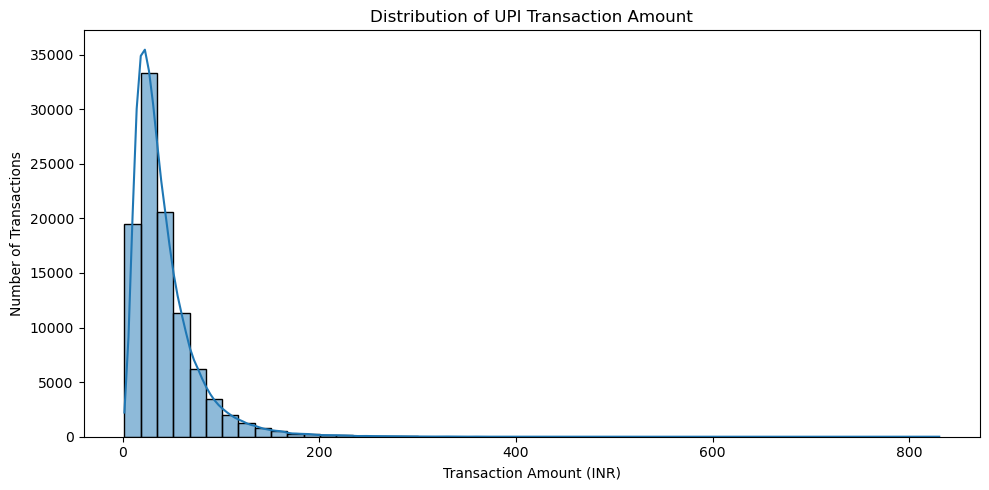

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=transaction_clean,
    x="amount",
    bins=50,
    kde=True
)

plt.title("Distribution of UPI Transaction Amount")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

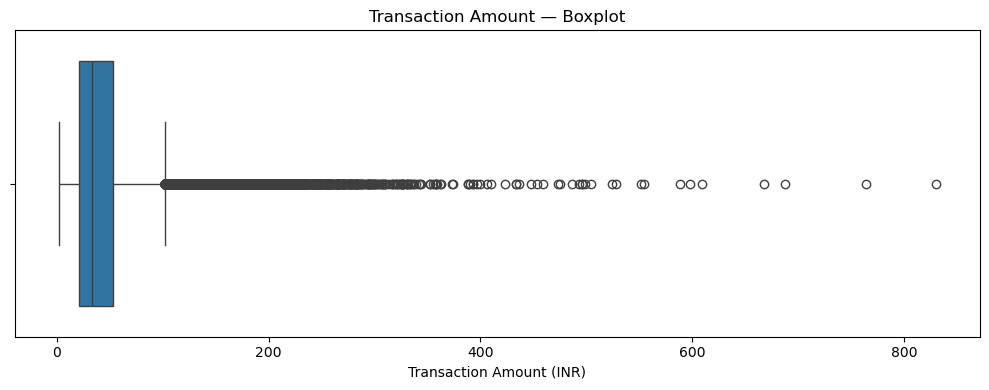

In [49]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=transaction_clean,
    x="amount"
)

plt.title("Transaction Amount — Boxplot")
plt.xlabel("Transaction Amount (INR)")

plt.tight_layout()
plt.show()

#### Descriptive Observation — Transaction Amount

The mean transaction amount is approximately **₹42.42**, while the median is
approximately **₹33.09**. The maximum observed amount is **₹830.46**.

The mean being above the median, together with the high-value observations
identified by the IQR analysis, indicates a right-skewed transaction-value
distribution.

The **5,457** statistical outliers are retained for subsequent fraud and
risk analysis rather than being removed.

### 6.7.2 Transaction and Fraud Trends Over Time

Before interpreting monthly trends, the available transaction date range is
checked so that partially covered beginning or ending months are not
mistaken for true changes in business performance.

In [50]:
transaction_date_coverage = transaction_clean["timestamp"].agg(
    ["min", "max"]
)

transaction_date_coverage

min   2020-10-18 17:38:50.925715
max   2025-08-06 08:06:00.531194
Name: timestamp, dtype: datetime64[ns]

#### Date-Coverage Note

The transaction dataset spans from **18 October 2020 to 6 August 2025**.

Therefore:

- **October 2020** contains only a partial month of observations.
- **August 2025** contains only the first six days of observations.

To avoid misleading month-to-month comparisons, the monthly trend charts use
only complete months from **November 2020 through July 2025**.

In [51]:
transaction_clean["transaction_month"] = (
    transaction_clean["timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

In [52]:
monthly_transactions = (
    transaction_clean
    .groupby("transaction_month")
    .agg(
        transaction_volume=("transaction_id", "count"),
        total_transaction_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_transactions.tail()

,transaction_month,transaction_volume,total_transaction_amount
54,2025-04-01,6333,265777.29
55,2025-05-01,8129,349421.79
56,2025-06-01,10568,450829.32
57,2025-07-01,18377,777212.59
58,2025-08-01,6841,287377.21


In [53]:
monthly_transactions_complete = monthly_transactions[
    (monthly_transactions["transaction_month"] > "2020-10-01") &
    (monthly_transactions["transaction_month"] < "2025-08-01")
]

monthly_transactions_complete.tail(12)

,transaction_month,transaction_volume,total_transaction_amount
46,2024-08-01,2284,98527.51
47,2024-09-01,2541,107465.80
48,2024-10-01,2779,117295.12
49,2024-11-01,3105,129344.40
50,2024-12-01,3579,151560.70
51,2025-01-01,4122,172934.35
52,2025-02-01,4178,177099.82
53,2025-03-01,5497,234435.91
54,2025-04-01,6333,265777.29
55,2025-05-01,8129,349421.79


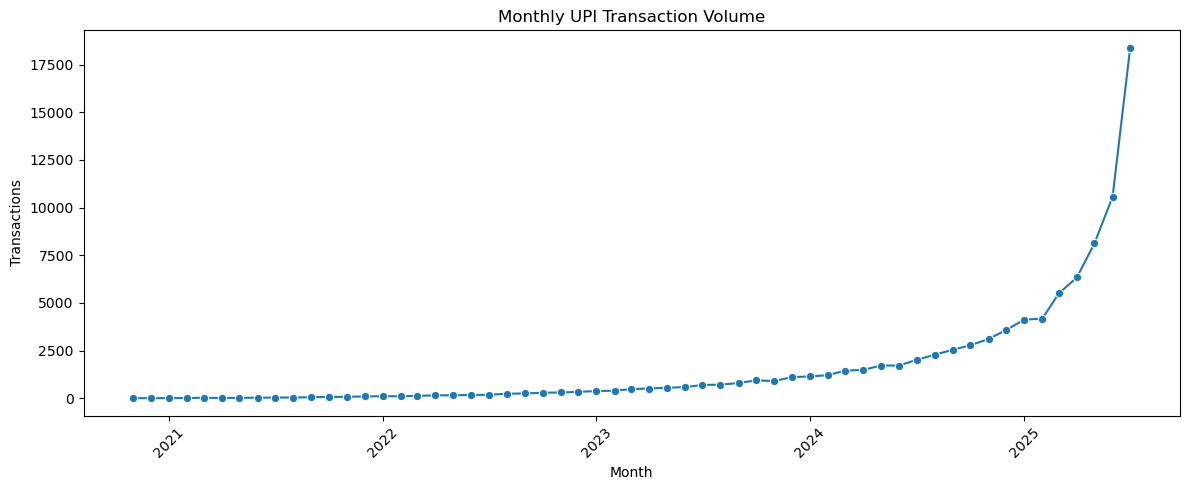

In [54]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_transactions_complete,
    x="transaction_month",
    y="transaction_volume",
    marker="o"
)

plt.title("Monthly UPI Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [55]:
monthly_fraud = (
    transaction_clean
    .groupby("transaction_month")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
    .reset_index()
)

monthly_fraud["fraud_rate"] = (
    monthly_fraud["fraud_transactions"] /
    monthly_fraud["total_transactions"]
)

monthly_fraud.tail()

,transaction_month,total_transactions,fraud_transactions,fraud_rate
54,2025-04-01,6333,101,0.015948
55,2025-05-01,8129,163,0.020052
56,2025-06-01,10568,213,0.020155
57,2025-07-01,18377,371,0.020188
58,2025-08-01,6841,145,0.021196


In [56]:
monthly_fraud_complete = monthly_fraud[
    (monthly_fraud["transaction_month"] > "2020-10-01") &
    (monthly_fraud["transaction_month"] < "2025-08-01")
]
monthly_fraud_complete.tail(12)

,transaction_month,total_transactions,fraud_transactions,fraud_rate
46,2024-08-01,2284,40,0.017513
47,2024-09-01,2541,53,0.020858
48,2024-10-01,2779,52,0.018712
49,2024-11-01,3105,75,0.024155
50,2024-12-01,3579,67,0.018720
51,2025-01-01,4122,69,0.016739
52,2025-02-01,4178,98,0.023456
53,2025-03-01,5497,108,0.019647
54,2025-04-01,6333,101,0.015948
55,2025-05-01,8129,163,0.020052


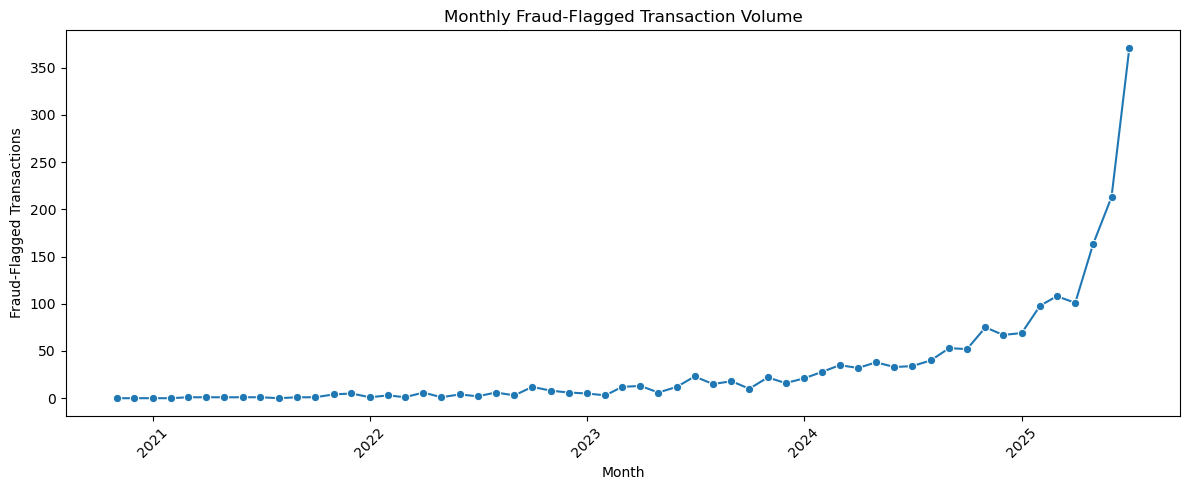

In [57]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_fraud_complete,
    x="transaction_month",
    y="fraud_transactions",
    marker="o"
)

plt.title("Monthly Fraud-Flagged Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Fraud-Flagged Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 6.7.3 Grouped Descriptive Statistics

Transaction amount is summarized using transaction count, mean, median, and
standard deviation across device type, customer region, and merchant type.

In [58]:
device_type_stats = (
    transaction_enriched_df
    .groupby("device_type")["amount"]
    .agg(
        transaction_count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
)

device_type_stats

,device_type,transaction_count,mean,median,std
0,android,25145,42.376283,33.030,34.035585
1,feature_phone,25596,42.216250,32.820,33.981463
2,ios,24783,42.542170,33.090,34.501120
3,tablet,24476,42.545060,33.415,34.233864


In [59]:
region_stats = (
    transaction_enriched_df
    .groupby("customer_region")["amount"]
    .agg(
        transaction_count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
)

region_stats

,customer_region,transaction_count,mean,median,std
0,central,19677,42.488194,33.34,34.537385
1,east,20078,42.527747,32.91,34.311902
2,north,20787,42.213204,33.07,34.176362
3,south,19372,42.539278,33.14,34.240232
4,west,20086,42.333227,33.05,33.669879


In [60]:
merchant_type_stats = (
    transaction_enriched_df
    .dropna(subset=["merchant_type"])
    .groupby("merchant_type")["amount"]
    .agg(
        transaction_count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
)

merchant_type_stats

,merchant_type,transaction_count,mean,median,std
0,apparel,5986,42.099579,32.820,33.773058
1,electronics,5485,42.662551,33.120,34.321255
2,food,4811,42.393157,33.460,33.131053
3,grocery,4488,41.751611,32.545,32.775837
4,online,5171,42.988874,33.220,35.583800
5,transport,4208,42.890055,33.405,35.754099


#### Descriptive Observation — Group Comparisons

Average transaction amounts are relatively similar across the observed
groups:

- Device-type means are approximately ₹42.22–₹42.55.
- Customer-region means are approximately ₹42.21–₹42.54.
- Merchant-type means are approximately ₹41.75–₹42.99.

These differences are descriptive and should not be treated as statistically
significant without the formal tests performed in Step 7.

### 6.7.4 Transaction Amount Patterns by Device Type

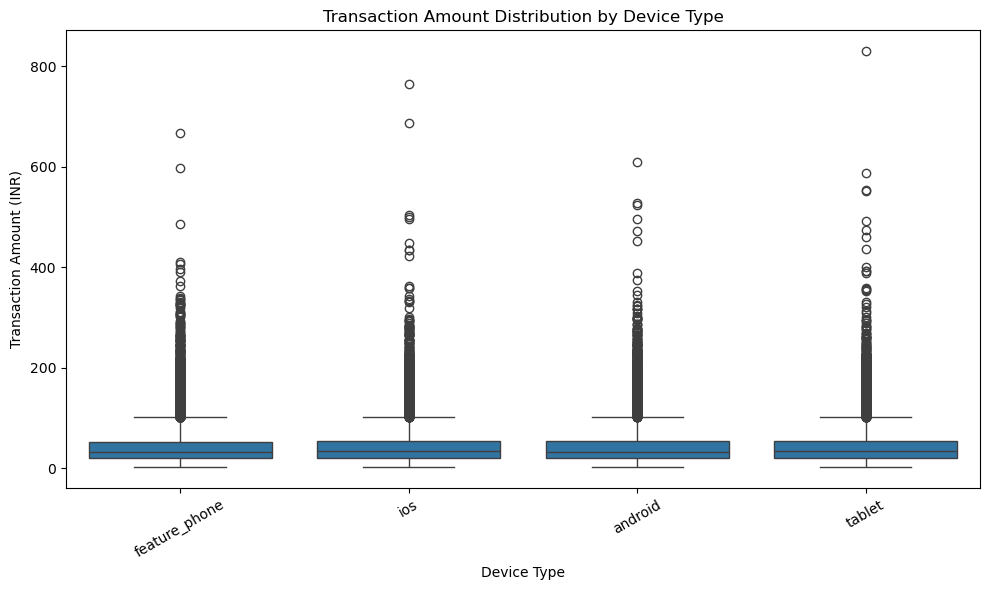

In [61]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=transaction_enriched_df,
    x="device_type",
    y="amount"
)

plt.title("Transaction Amount Distribution by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Transaction Amount (INR)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

The boxplot provides a visual comparison of transaction-value distributions
across device types and highlights within-group high-value observations.
Formal comparison between groups is deferred to Step 7.

### 6.7.5 Fraud Rate by Customer Region and Channel

In [62]:
region_channel_fraud = (
    transaction_enriched_df
    .pivot_table(
        index="customer_region",
        columns="channel",
        values="fraud_flag",
        aggfunc="mean"
    ) * 100
)

region_channel_fraud

channel,app,intent,qr_code
customer_region,,,
central,2.037093,1.721774,2.065483
east,2.092050,1.781670,2.129233
north,2.039340,1.974249,1.816069
south,1.915354,2.217742,1.953488
west,1.997913,1.737968,2.527456


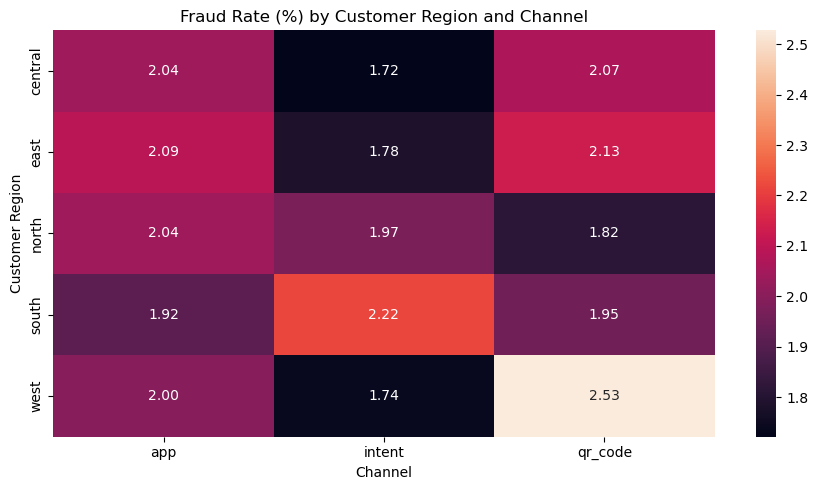

In [63]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    region_channel_fraud,
    annot=True,
    fmt=".2f"
)

plt.title("Fraud Rate (%) by Customer Region and Channel")
plt.xlabel("Channel")
plt.ylabel("Customer Region")

plt.tight_layout()
plt.show()

#### Descriptive Observation — Region × Channel Fraud Pattern

Observed fraud rates across customer-region/channel combinations range from
approximately **1.72% to 2.53%**.

The highest observed combination in this table is **West × QR Code
(~2.53%)**, while **Central × Intent (~1.72%)** is the lowest.

These differences are descriptive. Formal association between fraud and
channel will be evaluated statistically in Step 7.

### 6.7.6 Merchant Failure Patterns by Region and Merchant Type

In [64]:
merchant_analysis = (
    transaction_enriched_df
    .dropna(subset=["merchant_id"])
    .copy()
)

merchant_analysis["is_failed"] = (
    merchant_analysis["status"] == "failed"
)

merchant_failure_heatmap = (
    merchant_analysis
    .pivot_table(
        index="merchant_region",
        columns="merchant_type",
        values="is_failed",
        aggfunc="mean"
    ) * 100
)
merchant_failure_heatmap

merchant_type,apparel,electronics,food,grocery,online,transport
merchant_region,,,,,,
central,6.322674,6.025641,4.551539,3.828484,6.694915,5.775764
east,5.165456,5.865922,4.780488,5.517241,5.882353,7.153076
north,5.450734,6.025370,5.336427,5.174036,5.900305,5.699020
south,5.865522,5.834829,4.148148,6.119792,6.462882,5.810398
west,5.237712,5.935697,6.535948,5.763397,5.817783,5.889282


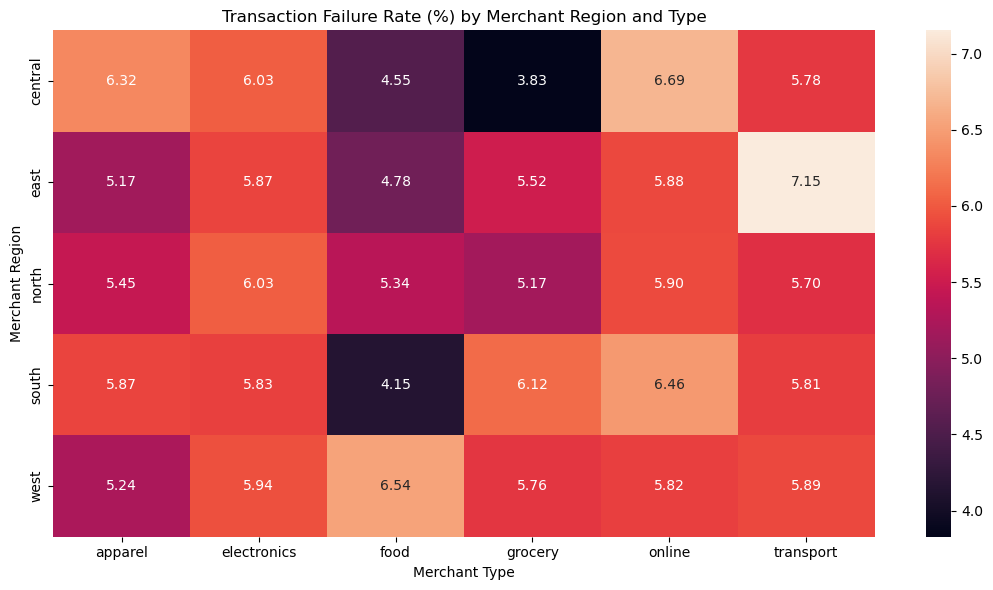

In [65]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    merchant_failure_heatmap,
    annot=True,
    fmt=".2f"
)

plt.title("Transaction Failure Rate (%) by Merchant Region and Type")
plt.xlabel("Merchant Type")
plt.ylabel("Merchant Region")

plt.tight_layout()
plt.show()

#### Descriptive Observation — Merchant Failure Pattern

Observed merchant failure rates vary across the region × merchant-type
combinations, ranging from approximately **3.83% to 7.15%**.

The highest observed combination is **East × Transport (~7.15%)**, while
**Central × Grocery (~3.83%)** is the lowest.

These are descriptive differences only. Their statistical significance will
be evaluated separately in Step 7.

### 6.7.7 High-Activity Entity Rankings

High-activity customers, merchants, and devices are identified using
transaction counts. These rankings support the assignment requirement to
identify high-activity segments.

In [66]:
top_customers = (
    customer_metrics_df
    .sort_values(
        "number_of_transactions",
        ascending=False
    )
    .head(10)
)

top_customers

,customer_id,total_transaction_amount,number_of_transactions,transaction_value_per_customer
1181,cust101660,3141.59,71,44.247746
4219,cust105966,2976.41,59,50.447627
1835,cust102584,2427.52,57,42.588070
593,cust100835,2279.42,56,40.703929
2830,cust103960,2351.67,56,41.994107
3370,cust104708,2283.09,55,41.510727
3154,cust104396,2154.32,54,39.894815
1946,cust102733,2221.64,54,41.141481
4619,cust106552,2282.31,54,42.265000
2528,cust103519,2200.34,53,41.515849


In [67]:
top_merchants = (
    merchant_metrics_df
    .sort_values(
        "total_transactions",
        ascending=False
    )
    .head(10)
)

top_merchants

,merchant_id,total_transactions,fraud_transactions,total_transaction_amount,merchant_fraud_ratio
310,merch1310,85,3,3680.83,0.035294
138,merch1138,82,1,3444.95,0.012195
131,merch1131,82,0,4340.38,0.000000
476,merch1476,81,0,2979.30,0.000000
318,merch1318,80,2,3592.35,0.025000
4,merch1004,80,1,4168.88,0.012500
315,merch1315,80,0,3397.30,0.000000
212,merch1212,78,0,3302.82,0.000000
487,merch1487,77,1,3150.41,0.012987
448,merch1448,76,1,3437.76,0.013158


In [68]:
top_devices = (
    device_metrics_df
    .sort_values(
        "total_transactions",
        ascending=False
    )
    .head(10)
)

top_devices

,device_id,total_transactions,fraud_transactions,total_transaction_amount,device_fraud_ratio
1180,dev101660,71,1,3141.59,0.014085
4211,dev105966,59,0,2976.41,0.000000
1833,dev102584,57,1,2427.52,0.017544
593,dev100835,56,0,2279.42,0.000000
3364,dev104708,55,1,2283.09,0.018182
3148,dev104396,54,1,2154.32,0.018519
4610,dev106552,54,1,2282.31,0.018519
2554,dev103560,53,0,2459.71,0.000000
6796,dev109685,53,0,2719.75,0.000000
5816,dev108268,51,0,1771.01,0.000000


### 6.7.8 Merchant and Device Fraud-Ratio Rankings

Merchant and device fraud ratios are ranked descriptively to identify
entities requiring closer analytical review.

Fraud ratio must be interpreted together with the number of transactions
used to calculate the ratio.

In [69]:
merchant_risk_ranking = (
    merchant_metrics_df
    .sort_values(
        [
            "merchant_fraud_ratio",
            "total_transactions"
        ],
        ascending=[False, False]
    )
)

merchant_risk_ranking[
    [
        "merchant_id",
        "total_transactions",
        "fraud_transactions",
        "merchant_fraud_ratio"
    ]
].head(10)

,merchant_id,total_transactions,fraud_transactions,merchant_fraud_ratio
201,merch1201,47,5,0.106383
305,merch1305,46,4,0.086957
358,merch1358,62,5,0.080645
80,merch1080,66,5,0.075758
364,merch1364,54,4,0.074074
203,merch1203,70,5,0.071429
231,merch1231,57,4,0.070175
307,merch1307,57,4,0.070175
51,merch1051,43,3,0.069767
180,merch1180,73,5,0.068493


In [70]:
device_risk_ranking = (
    device_metrics_df
    .sort_values(
        [
            "device_fraud_ratio",
            "total_transactions"
        ],
        ascending=[False, False]
    )
)

device_risk_ranking[
    [
        "device_id",
        "total_transactions",
        "fraud_transactions",
        "device_fraud_ratio"
    ]
].head(10)

,device_id,total_transactions,fraud_transactions,device_fraud_ratio
999,dev101401,1,1,1.000000
7783,dev201118,1,1,1.000000
7848,dev201223,1,1,1.000000
394,dev100572,9,7,0.777778
6104,dev108688,3,2,0.666667
6168,dev108780,15,8,0.533333
4934,dev107022,10,5,0.500000
2273,dev103168,8,4,0.500000
2751,dev103849,8,4,0.500000
2110,dev102949,6,3,0.500000


> **Interpretation caution:** Very high fraud ratios can result from very
small transaction counts. No arbitrary minimum-volume threshold is introduced
at this stage; therefore both the fraud ratio and its transaction denominator
must be considered together.

### 6.7.9 Rooted Device vs Fraud — Descriptive Comparison

This analysis provides an initial descriptive view of the Step-1 hypothesis
that rooted devices may be associated with higher fraud occurrence.
Formal hypothesis testing is reserved for Step 7.

In [71]:
rooted_fraud_summary = (
    transaction_enriched_df
    .groupby("is_rooted")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum"),
        average_amount=("amount", "mean")
    )
    .reset_index()
)

rooted_fraud_summary["fraud_rate"] = (
    rooted_fraud_summary["fraud_transactions"] /
    rooted_fraud_summary["total_transactions"]
)

rooted_fraud_summary

,is_rooted,total_transactions,fraud_transactions,average_amount,fraud_rate
0,False,96829,1344,42.435858,0.013880
1,True,3171,656,41.864566,0.206875


#### Descriptive Observation — Rooted Devices

Fraud-flagged transactions represent approximately **20.69%** of
transactions performed on rooted devices, compared with approximately
**1.39%** for non-rooted devices.

This is a substantial descriptive difference in the observed dataset.
However, it does not by itself establish causation or statistical
significance. The association will be tested formally in Step 7.

### 6.7.10 Customer Risk Score and Fraud — Descriptive View

Customer risk scores are compared between fraud-flagged and non-fraud
transactions to provide descriptive context for the formal risk-score
analysis in Step 7.

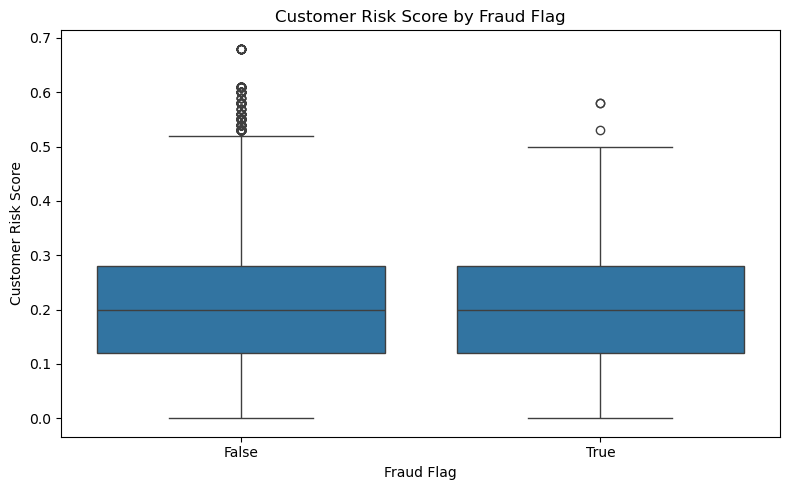

In [72]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=transaction_enriched_df,
    x="fraud_flag",
    y="customer_risk_score"
)

plt.title("Customer Risk Score by Fraud Flag")
plt.xlabel("Fraud Flag")
plt.ylabel("Customer Risk Score")
plt.tight_layout()
plt.show()

#### Descriptive Observation — Customer Risk Score

The customer risk-score distributions for fraud-flagged and non-fraud
transactions show substantial overlap, with broadly similar central
distributions in the boxplot.

No strong relationship should be inferred from this visualization alone.

The relationship between customer `risk_score` and fraud occurrence will be
evaluated formally using correlation and/or appropriate statistical analysis
in Step 7.

## 6.8 Step 6 Interim Conclusion

The seven SQL-extracted datasets were successfully prepared for analytical
use without unnecessary deletion or arbitrary imputation.

Context-dependent missing values were retained, applicable date and Boolean
fields were standardized, numerical domains were validated, and transaction
amount outliers were identified and retained for further investigation.
Normalized and standardized versions of transaction amount and risk scores
were created while preserving the original business values.

An enriched transaction-level analytical dataset was created without
changing the original transaction row count. Assignment-defined customer,
merchant, device, and failure-rate metrics were also calculated.

Exploratory analysis examined transaction-value distributions, transaction
and fraud trends, customer regions, merchant segments, device usage,
high-activity entities, fraud-ratio rankings, and rooted-device fraud
patterns.

The findings in Step 6 are descriptive. Formal hypothesis testing,
statistical significance, confidence intervals, assumptions, and limitations
will be addressed separately in Step 7.

# Step 7 — Statistical Analysis & Hypothesis Testing
### Inferential Validation of Fraud, Reliability & Risk Hypotheses

### Objective

Validate the business hypotheses developed earlier in the project using
appropriate inferential statistical tests.

The analysis reports statistical significance, effect size, confidence
intervals where appropriate, and practical interpretation.

> **Statistical principle:** A statistically significant result does not
automatically imply a large or practically important business effect.
Effect sizes and observed rates are interpreted alongside p-values.

## 7.1 Statistical Analysis Setup

A significance level of **α = 0.05** is defined before testing.

For each hypothesis:

- **H₀ (Null Hypothesis):** No association or difference exists for the relationship being tested.
- **H₁ (Alternative Hypothesis):** An association or difference exists.

When p < 0.05, reject H₀. Otherwise, fail to reject H₀.

In [73]:
import numpy as np

from scipy import stats

from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

In [74]:
ALPHA = 0.05

def hypothesis_decision(p_value, alpha=ALPHA):
    if p_value < alpha:
        return "Reject H0"
    return "Fail to reject H0"

In [75]:
def cramers_v(contingency_table):
    
    chi2, p_value, dof, expected = stats.chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    v = np.sqrt(
        (chi2 / n) /
        min(rows - 1, cols - 1)
    )

    return chi2, p_value, dof, expected, v

## 7.2 Statistical Test Plan

| Business Hypothesis | Variables | Statistical Test |
|---|---|---|
| Rooted devices are associated with fraud | `is_rooted` × `fraud_flag` | Chi-square + Cramér's V + Risk Ratio |
| Fraud occurrence differs by channel | `channel` × `fraud_flag` | Chi-square + Cramér's V |
| Transaction status differs by device type | `device_type` × `status` | Chi-square + Cramér's V |
| Merchant failure rate differs by region | `merchant_region` × failure status | Chi-square + Cramér's V |
| Mean transaction amount differs by device type | `amount` across `device_type` | Welch ANOVA |
| Customer risk score relates to fraud occurrence | customer `risk_score` × customer fraud rate | Spearman correlation |

### Test-Selection Rationale

Statistical tests were selected according to variable type and number of
comparison groups.

- Chi-square tests are used for relationships between categorical variables.
- Welch ANOVA is used for transaction amount across multiple device-type
  groups rather than multiple pairwise t-tests.
- Spearman correlation is used for the customer-level risk-score analysis
  because it does not require normality and evaluates monotonic association.

This approach avoids unnecessary pairwise testing and keeps each statistical
method aligned with the structure of the supplied data.

## 7.3 Hypothesis 1 — Rooted Device Status and Fraud

### Hypotheses

**H₀:** Rooted-device status and fraud occurrence are independent.

**H₁:** Rooted-device status and fraud occurrence are associated.

Because both variables are categorical, a **Chi-square Test of Independence**
is used.

Cramér's V is reported as an effect-size measure, and a risk ratio with a
95% confidence interval is calculated for business interpretation.

In [76]:
rooted_fraud_table = pd.crosstab(
    transaction_enriched_df["is_rooted"],
    transaction_enriched_df["fraud_flag"]
)

rooted_fraud_table

fraud_flag,False,True
is_rooted,,
False,95485,1344
True,2515,656


In [77]:
(
    chi2_rooted,
    p_rooted,
    dof_rooted,
    expected_rooted,
    v_rooted
) = cramers_v(rooted_fraud_table)

print("Chi-square statistic:", chi2_rooted)
print("Degrees of freedom:", dof_rooted)
if p_rooted < 0.001:
    print("p-value: < 0.001")
else:
    print(f"p-value: {p_rooted:.3f}")
print("Cramer's V:", v_rooted)
print("Minimum expected frequency:", expected_rooted.min())
print("Decision:", hypothesis_decision(p_rooted))

Chi-square statistic: 5825.09513087714
Degrees of freedom: 1
p-value: < 0.001
Cramer's V: 0.24135233851937585
Minimum expected frequency: 63.42
Decision: Reject H0


In [78]:
rooted_ci = rooted_fraud_summary.copy()

confidence_intervals = []

for _, row in rooted_ci.iterrows():

    lower, upper = proportion_confint(
        count=int(row["fraud_transactions"]),
        nobs=int(row["total_transactions"]),
        alpha=0.05,
        method="wilson"
    )

    confidence_intervals.append((lower, upper))

rooted_ci[["ci_lower", "ci_upper"]] = pd.DataFrame(
    confidence_intervals,
    index=rooted_ci.index
)

rooted_ci

,is_rooted,total_transactions,fraud_transactions,average_amount,fraud_rate,ci_lower,ci_upper
0,False,96829,1344,42.435858,0.013880,0.013162,0.014637
1,True,3171,656,41.864566,0.206875,0.193135,0.221324


In [79]:
a = rooted_fraud_table.loc[True, True]
b = rooted_fraud_table.loc[True, False]

c = rooted_fraud_table.loc[False, True]
d = rooted_fraud_table.loc[False, False]

rooted_risk = a / (a + b)
non_rooted_risk = c / (c + d)

risk_ratio = rooted_risk / non_rooted_risk

se_log_rr = np.sqrt(
    (1 / a) - (1 / (a + b)) +
    (1 / c) - (1 / (c + d))
)

z_critical = stats.norm.ppf(0.975)

rr_lower = np.exp(
    np.log(risk_ratio) - z_critical * se_log_rr
)

rr_upper = np.exp(
    np.log(risk_ratio) + z_critical * se_log_rr
)

print(f"Rooted fraud rate: {rooted_risk:.2%}")
print(f"Non-rooted fraud rate: {non_rooted_risk:.2%}")
print(f"Risk Ratio: {risk_ratio:.2f}")
print(
    f"95% CI for Risk Ratio: "
    f"({rr_lower:.2f}, {rr_upper:.2f})"
)

Rooted fraud rate: 20.69%
Non-rooted fraud rate: 1.39%
Risk Ratio: 14.90
95% CI for Risk Ratio: (13.67, 16.25)


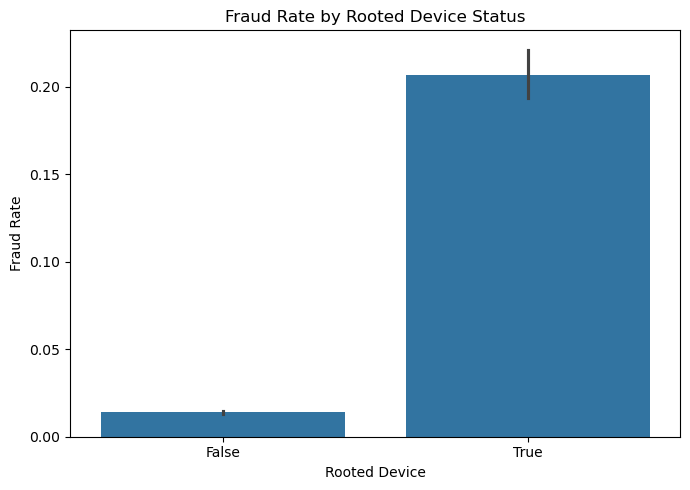

In [80]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=transaction_enriched_df,
    x="is_rooted",
    y="fraud_flag",
    errorbar=("ci", 95)
)

plt.title("Fraud Rate by Rooted Device Status")
plt.xlabel("Rooted Device")
plt.ylabel("Fraud Rate")
plt.tight_layout()

plt.show()

### Result Interpretation

The Chi-square test provides strong evidence of an association between
rooted-device status and fraud occurrence
(**χ² = 5825.10, p < 0.001**).

Cramér's V is approximately **0.241**, indicating a clearly non-negligible
association relative to the other categorical relationships examined in this
analysis.

The observed fraud rate is approximately:

- **20.69%** for transactions on rooted devices
- **1.39%** for transactions on non-rooted devices

The estimated **risk ratio is 14.90**, with a **95% confidence interval of
13.67–16.25**. Therefore, fraud-flagged transactions are approximately
14.9 times as prevalent among rooted-device transactions in the supplied
dataset.

**Decision:** Reject H₀.

> This establishes statistical association within the supplied dataset, not
> proof that rooting a device causes fraud.

## 7.4 Hypothesis 2 — Transaction Channel and Fraud

### Hypotheses

**H₀:** Transaction channel and fraud occurrence are independent.

**H₁:** Transaction channel and fraud occurrence are associated.

A Chi-square Test of Independence is used because both variables are
categorical.

In [81]:
channel_fraud_table = pd.crosstab(
    transaction_enriched_df["channel"],
    transaction_enriched_df["fraud_flag"]
)

channel_fraud_table

fraud_flag,False,True
channel,,
app,32692,673
intent,32727,629
qr_code,32581,698


In [82]:
(
    chi2_channel,
    p_channel,
    dof_channel,
    expected_channel,
    v_channel
) = cramers_v(channel_fraud_table)

print("Chi-square statistic:", chi2_channel)
print("Degrees of freedom:", dof_channel)
print("p-value:", p_channel)
print("Cramer's V:", v_channel)
print("Minimum expected frequency:", expected_channel.min())
print("Decision:", hypothesis_decision(p_channel))

Chi-square statistic: 3.8837426371196555
Degrees of freedom: 2
p-value: 0.14343528536611472
Cramer's V: 0.006231968097735783
Minimum expected frequency: 665.58
Decision: Fail to reject H0


In [83]:
channel_fraud_rates = (
    transaction_enriched_df
    .groupby("channel")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
    .reset_index()
)

channel_fraud_rates["fraud_rate"] = (
    channel_fraud_rates["fraud_transactions"] /
    channel_fraud_rates["total_transactions"]
)

channel_fraud_rates

,channel,total_transactions,fraud_transactions,fraud_rate
0,app,33365,673,0.020171
1,intent,33356,629,0.018857
2,qr_code,33279,698,0.020974


### Result Interpretation

Observed fraud rates differ slightly across transaction channels:

- App: approximately **2.02%**
- Intent: approximately **1.89%**
- QR Code: approximately **2.10%**

However, the Chi-square test does not provide statistically significant
evidence of an association between transaction channel and fraud occurrence
(**χ² = 3.88, p = 0.143**).

Cramér's V is approximately **0.006**, indicating an extremely small observed
association.

**Decision:** Fail to reject H₀.

The small descriptive differences between channels should therefore not be
interpreted as evidence that one channel has a systematically different fraud
rate in the supplied dataset.

## 7.5 Hypothesis 3 — Device Type and Transaction Status

### Hypotheses

**H₀:** Transaction status and device type are independent.

**H₁:** Transaction status and device type are associated.

In [84]:
device_status_table = pd.crosstab(
    transaction_enriched_df["device_type"],
    transaction_enriched_df["status"]
)

device_status_table

status,failed,pending,success
device_type,,,
android,1525,529,23091
feature_phone,1486,496,23614
ios,1461,474,22848
tablet,1399,490,22587


In [85]:
(
    chi2_device_status,
    p_device_status,
    dof_device_status,
    expected_device_status,
    v_device_status
) = cramers_v(device_status_table)

print("Chi-square statistic:", chi2_device_status)
print("Degrees of freedom:", dof_device_status)
print("p-value:", p_device_status)
print("Cramer's V:", v_device_status)
print(
    "Minimum expected frequency:",
    expected_device_status.min()
)
print(
    "Decision:",
    hypothesis_decision(p_device_status)
)

Chi-square statistic: 5.934359154129779
Degrees of freedom: 6
p-value: 0.43058329992775024
Cramer's V: 0.005447182369872418
Minimum expected frequency: 486.82764
Decision: Fail to reject H0


In [86]:
device_status_percent = (
    pd.crosstab(
        transaction_enriched_df["device_type"],
        transaction_enriched_df["status"],
        normalize="index"
    ) * 100
)

device_status_percent

status,failed,pending,success
device_type,,,
android,6.064824,2.103798,91.831378
feature_phone,5.805595,1.937803,92.256603
ios,5.895170,1.912601,92.192229
tablet,5.715803,2.001961,92.282236


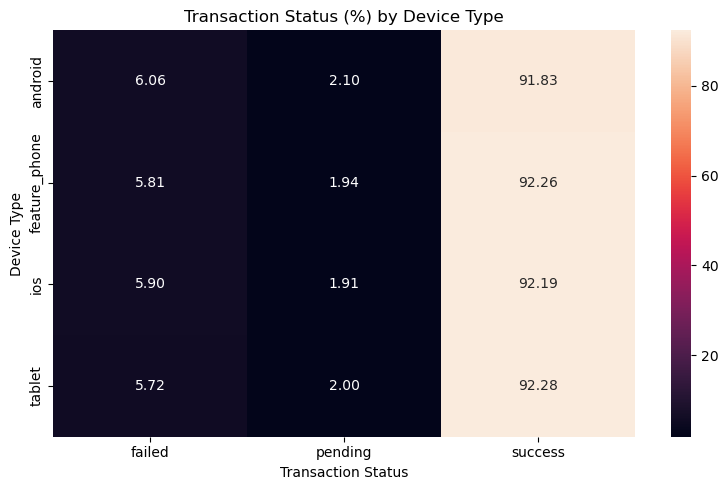

In [87]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    device_status_percent,
    annot=True,
    fmt=".2f"
)

plt.title("Transaction Status (%) by Device Type")
plt.xlabel("Transaction Status")
plt.ylabel("Device Type")
plt.tight_layout()

plt.show()

### Result Interpretation

Transaction-status distributions are very similar across device types.
Observed success rates range only from approximately **91.83% to 92.28%**.

The Chi-square test finds no statistically significant association between
device type and transaction status
(**χ² = 5.93, p = 0.431**).

Cramér's V is approximately **0.005**, indicating a negligible association.

**Decision:** Fail to reject H₀.

The supplied data therefore does not provide evidence that transaction status
systematically varies by device type.

## 7.6 Hypothesis 4 — Merchant Region and Transaction Failure

### Hypotheses

**H₀:** Merchant region and transaction failure are independent.

**H₁:** Transaction failure is associated with merchant region.

Only merchant-linked transactions are included because merchant region is
not applicable to Send/Receive transactions without a merchant reference.

In [88]:
merchant_region_failure_table = pd.crosstab(
    merchant_analysis["merchant_region"],
    merchant_analysis["is_failed"]
)

merchant_region_failure_table

is_failed,False,True
merchant_region,,
central,5296,323
east,6003,359
north,6458,381
south,4762,293
west,5907,367


In [89]:
merchant_region_failure_rates = (
    merchant_analysis
    .groupby("merchant_region")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("is_failed", "sum")
    )
    .reset_index()
)

merchant_region_failure_rates["failure_rate"] = (
    merchant_region_failure_rates["failed_transactions"] /
    merchant_region_failure_rates["total_transactions"]
)

merchant_region_failure_rates

,merchant_region,total_transactions,failed_transactions,failure_rate
0,central,5619,323,0.057484
1,east,6362,359,0.056429
2,north,6839,381,0.055710
3,south,5055,293,0.057962
4,west,6274,367,0.058495


In [90]:
(
    chi2_merchant,
    p_merchant,
    dof_merchant,
    expected_merchant,
    v_merchant
) = cramers_v(merchant_region_failure_table)

print("Chi-square statistic:", chi2_merchant)
print("Degrees of freedom:", dof_merchant)
print("p-value:", p_merchant)
print("Cramer's V:", v_merchant)
print("Minimum expected frequency:", expected_merchant.min())
print("Decision:", hypothesis_decision(p_merchant))

Chi-square statistic: 0.6089090950379081
Degrees of freedom: 4
p-value: 0.962068557398709
Cramer's V: 0.004494069398418305
Minimum expected frequency: 288.8906763076719
Decision: Fail to reject H0


### Result Interpretation

Merchant-linked transaction failure rates are broadly similar across regions,
ranging from approximately **5.57% to 5.85%**.

The Chi-square test provides no statistically significant evidence that
transaction failure is associated with merchant region
(**χ² = 0.61, p = 0.962**).

Cramér's V is approximately **0.004**, indicating a negligible observed
association.

**Decision:** Fail to reject H₀.

Therefore, although individual region × merchant-type combinations showed
descriptive variation in Step 6, merchant region alone does not appear to
explain overall transaction failure differences.

## 7.7 Hypothesis 5 — Transaction Amount by Device Type

### Test: Welch One-Way ANOVA

### Hypotheses

**H₀:** Mean transaction amount is equal across device types.

**H₁:** At least one device type has a different mean transaction amount.

Transaction amount is numerical and device type contains multiple groups.

A Welch one-way ANOVA is used because it is more robust than classical
ANOVA when group variances differ.

In [91]:
device_amount_groups = [
    group["amount"].dropna().to_numpy()
    for _, group
    in transaction_enriched_df.groupby("device_type")
]

levene_result = stats.levene(
    *device_amount_groups,
    center="median"
)

print("Levene statistic:", levene_result.statistic)
print("Levene p-value:", levene_result.pvalue)

Levene statistic: 0.3283425564903639
Levene p-value: 0.8048747365375537


### Assumption Check

Levene's test is not statistically significant
(**p = 0.805**), providing no evidence of materially different group
variances.

A Welch ANOVA is nevertheless retained as a robust multi-group comparison.

In [92]:
welch_result = anova_oneway(
    device_amount_groups,
    use_var="unequal"
)

print("Welch F statistic:", welch_result.statistic)
print("p-value:", welch_result.pvalue)
print("Degrees of freedom:", welch_result.df)
print(
    "Decision:",
    hypothesis_decision(welch_result.pvalue)
)

Welch F statistic: 0.5326398574424384
p-value: 0.6598635864857816
Degrees of freedom: (3.0, np.float64(55518.13836366836))
Decision: Fail to reject H0


In [93]:
grand_mean = transaction_enriched_df["amount"].mean()

ss_between = sum(
    len(group) *
    (group["amount"].mean() - grand_mean) ** 2
    for _, group
    in transaction_enriched_df.groupby("device_type")
)

ss_total = (
    (
        transaction_enriched_df["amount"]
        - grand_mean
    ) ** 2
).sum()

eta_squared = ss_between / ss_total

print("Eta-squared:", eta_squared)

Eta-squared: 1.593987068223644e-05


### Result Interpretation

The Welch ANOVA does not identify a statistically significant difference in
mean transaction amount across device types
(**F ≈ 0.53, p = 0.660**).

The estimated eta-squared value is approximately **0.000016**, indicating
that device type explains virtually none of the observed variation in
transaction amount.

**Decision:** Fail to reject H₀.

The small differences in device-level average transaction amount observed
during Step 6 are therefore not statistically supported.


## 7.8 Hypothesis 6 — Customer Risk Score and Fraud Occurrence

### Test: Spearman Rank Correlation
### Hypotheses

**H₀:** Customer risk score has no monotonic relationship with customer fraud rate.

**H₁:** Customer risk score is associated with customer fraud rate.

Transactions are first aggregated to customer level. Spearman correlation is
used because fraud rate is bounded and does not need to satisfy a normality
assumption.

In [94]:
customer_fraud_analysis = (
    transaction_enriched_df
    .groupby("customer_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_flag", "sum")
    )
    .reset_index()
)

customer_fraud_analysis["fraud_rate"] = (
    customer_fraud_analysis["fraud_transactions"] /
    customer_fraud_analysis["total_transactions"]
)

In [95]:
customer_risk_analysis = (
    customer_clean[
        ["customer_id", "risk_score"]
    ]
    .merge(
        customer_fraud_analysis,
        on="customer_id",
        how="inner",
        validate="one_to_one"
    )
)

customer_risk_analysis.shape

(7032, 5)

In [96]:
spearman_result = stats.spearmanr(
    customer_risk_analysis["risk_score"],
    customer_risk_analysis["fraud_rate"]
)

rho_risk = spearman_result.statistic
p_risk = spearman_result.pvalue

print("Spearman correlation:", rho_risk)
print("p-value:", p_risk)
print("Decision:", hypothesis_decision(p_risk))

Spearman correlation: -0.00945232322347696
p-value: 0.428057266305632
Decision: Fail to reject H0


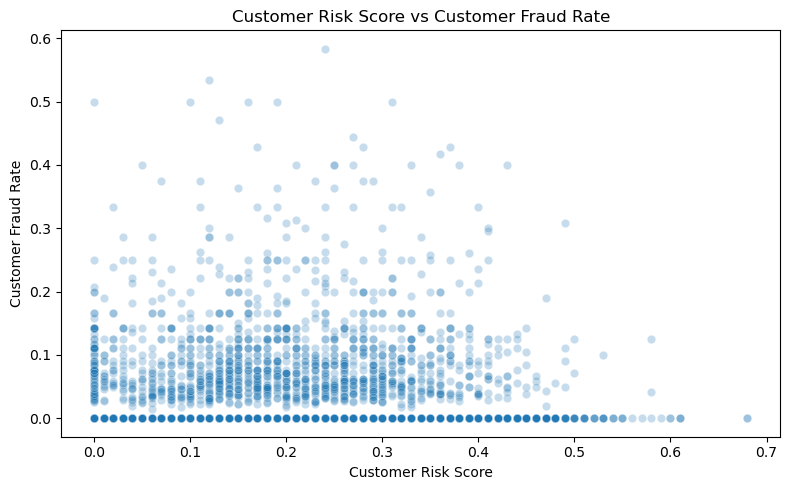

In [97]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=customer_risk_analysis,
    x="risk_score",
    y="fraud_rate",
    alpha=0.25
)

plt.title("Customer Risk Score vs Customer Fraud Rate")
plt.xlabel("Customer Risk Score")
plt.ylabel("Customer Fraud Rate")
plt.tight_layout()

plt.show()

### Result Interpretation

The customer-level Spearman correlation between risk score and observed fraud
rate is approximately **ρ = -0.0095**.

The relationship is not statistically significant
(**p = 0.428**) and the correlation magnitude is extremely close to zero.

**Decision:** Fail to reject H₀.

The supplied data therefore provides no evidence of a meaningful monotonic
relationship between customer `risk_score` and customer fraud rate.

This finding should not be interpreted to mean that the risk score has no
other operational value; it only indicates that the specific relationship
tested here is not supported by this dataset.

## 7.9 Consolidated Statistical Results

This section consolidates the six hypothesis tests into a single summary and
evaluates whether the conclusions remain stable after correcting for multiple
hypothesis testing.

> **Effect-size note:** Effect sizes in this summary use different statistical
> measures (Cramér's V, eta-squared, and Spearman's rho) and therefore should
> be interpreted within their respective tests rather than compared directly
> as if they were on the same scale.

### 7.9.1 Unadjusted Hypothesis-Test Summary

In [98]:
statistical_summary = pd.DataFrame([
    {
        "Hypothesis": "Rooted Device vs Fraud",
        "Test": "Chi-square",
        "Test_Statistic": chi2_rooted,
        "p_value": p_rooted,
        "Effect_Metric": "Cramer's V",
        "Effect_Size": v_rooted
    },
    {
        "Hypothesis": "Channel vs Fraud",
        "Test": "Chi-square",
        "Test_Statistic": chi2_channel,
        "p_value": p_channel,
        "Effect_Metric": "Cramer's V",
        "Effect_Size": v_channel
    },
    {
        "Hypothesis": "Device Type vs Status",
        "Test": "Chi-square",
        "Test_Statistic": chi2_device_status,
        "p_value": p_device_status,
        "Effect_Metric": "Cramer's V",
        "Effect_Size": v_device_status
    },
    {
        "Hypothesis": "Merchant Region vs Failure",
        "Test": "Chi-square",
        "Test_Statistic": chi2_merchant,
        "p_value": p_merchant,
        "Effect_Metric": "Cramer's V",
        "Effect_Size": v_merchant
    },
    {
        "Hypothesis": "Amount vs Device Type",
        "Test": "Welch ANOVA",
        "Test_Statistic": welch_result.statistic,
        "p_value": welch_result.pvalue,
        "Effect_Metric": "Eta-squared",
        "Effect_Size": eta_squared
    },
    {
        "Hypothesis": "Customer Risk Score vs Fraud Rate",
        "Test": "Spearman Correlation",
        "Test_Statistic": rho_risk,
        "p_value": p_risk,
        "Effect_Metric": "Spearman rho",
        "Effect_Size": rho_risk
    }
])

statistical_summary["p_display"] = (
    statistical_summary["p_value"]
    .apply(
        lambda p:
        "< 0.001" if p < 0.001
        else f"{p:.3f}"
    )
)

statistical_summary["Unadjusted_Decision"] = np.where(
    statistical_summary["p_value"] < ALPHA,
    "Reject H0",
    "Fail to reject H0"
)

statistical_summary[
    [
        "Hypothesis",
        "Test",
        "Test_Statistic",
        "p_display",
        "Effect_Metric",
        "Effect_Size",
        "Unadjusted_Decision"
    ]
]

,Hypothesis,Test,Test_Statistic,p_display,Effect_Metric,Effect_Size,Unadjusted_Decision
0,Rooted Device vs Fraud,Chi-square,5825.095131,< 0.001,Cramer's V,0.241352,Reject H0
1,Channel vs Fraud,Chi-square,3.883743,0.143,Cramer's V,0.006232,Fail to reject H0
2,Device Type vs Status,Chi-square,5.934359,0.431,Cramer's V,0.005447,Fail to reject H0
3,Merchant Region vs Failure,Chi-square,0.608909,0.962,Cramer's V,0.004494,Fail to reject H0
4,Amount vs Device Type,Welch ANOVA,0.532640,0.660,Eta-squared,0.000016,Fail to reject H0
5,Customer Risk Score vs Fraud Rate,Spearman Correlation,-0.009452,0.428,Spearman rho,-0.009452,Fail to reject H0


### 7.9.2 Multiple-Testing Adjustment — Holm Method

Because six hypotheses are evaluated within the same analytical phase, the
Holm procedure is applied to control the family-wise Type I error rate.

The original p-values are retained for transparency, while Holm-adjusted
p-values provide a more conservative decision criterion.

In [99]:
reject_holm, adjusted_p, _, _ = multipletests(
    statistical_summary["p_value"],
    alpha=ALPHA,
    method="holm"
)

statistical_summary["Holm_Adjusted_p"] = adjusted_p

statistical_summary["Holm_Decision"] = np.where(
    reject_holm,
    "Reject H0",
    "Fail to reject H0"
)

statistical_summary["Holm_p_display"] = (
    statistical_summary["Holm_Adjusted_p"]
    .apply(
        lambda p:
        "< 0.001" if p < 0.001
        else f"{p:.3f}"
    )
)

statistical_summary[
    [
        "Hypothesis",
        "p_display",
        "Holm_p_display",
        "Holm_Decision"
    ]
]

,Hypothesis,p_display,Holm_p_display,Holm_Decision
0,Rooted Device vs Fraud,< 0.001,< 0.001,Reject H0
1,Channel vs Fraud,0.143,0.717,Fail to reject H0
2,Device Type vs Status,0.431,1.000,Fail to reject H0
3,Merchant Region vs Failure,0.962,1.000,Fail to reject H0
4,Amount vs Device Type,0.660,1.000,Fail to reject H0
5,Customer Risk Score vs Fraud Rate,0.428,1.000,Fail to reject H0


### 7.9.3 Overall Statistical Interpretation

After Holm adjustment, the overall conclusion remains unchanged:

**Rooted Device Status ↔ Fraud Occurrence** is the only tested relationship
for which H₀ is rejected.

The tests for transaction channel, device type, merchant region, transaction
amount, and customer risk score all fail to reject their respective null
hypotheses.

This strengthens the evidence that rooted-device status is the primary
statistically supported risk signal among the hypotheses evaluated here.

## 7.10 Statistical Assumptions & Limitations

The statistical results should be interpreted with the following limitations:

1. The analysis is observational; statistically significant associations do
   not establish causation.

2. Several tests operate at transaction level. Multiple transactions may
   belong to the same customer, device, or merchant, so strict independence
   between every transaction may not hold perfectly.

3. The dataset contains a large number of transactions. Large samples can
   make small differences statistically detectable, so effect sizes and
   observed rates are considered alongside p-values.

4. Chi-square analyses require sufficiently large expected cell frequencies.
   Expected frequencies are checked for every contingency table.

5. Transaction amount is right-skewed and contains legitimate high-value
   observations. Welch ANOVA is used because it is robust to unequal group
   variances, but it does not eliminate sensitivity to extreme observations.
   The large group sizes provide additional robustness for comparison of
   group means, while the original outliers remain in the analysis.

6. Merchant-region analysis is limited to merchant-linked transactions;
   Send and Receive transactions without merchant references are excluded
   by design.

7. Customer risk-score correlation is evaluated at customer level using only
   customers with observed transactions in the transaction dataset.

These limitations mean the tests should be interpreted as evidence of
association within the supplied dataset rather than causal proof.

## 7.11 Step 7 Conclusion

Six business hypotheses were evaluated using Chi-square tests, Welch ANOVA,
and Spearman rank correlation at a predefined significance level of
**α = 0.05**.

The strongest and only statistically supported relationship was between
**rooted-device status and fraud occurrence**. Rooted-device transactions
showed an observed fraud rate of approximately **20.69%**, compared with
**1.39%** for non-rooted-device transactions. The estimated risk ratio was
approximately **14.90** with a **95% confidence interval of 13.67–16.25**.

The remaining analyses found no statistically significant evidence that:

- fraud occurrence differs systematically by transaction channel;
- transaction status is associated with device type;
- merchant-region differences explain transaction failure;
- mean transaction amount differs by device type; or
- customer risk score has a meaningful monotonic relationship with customer
  fraud rate.

The Holm multiple-testing correction did not change these conclusions.

Overall, the statistical results identify rooted-device status as the most
important validated risk signal among the hypotheses tested in this phase.
These findings represent associations within the supplied observational
dataset and should not be interpreted as causal effects.
